# Proyecto Final: Análisis Exploratorio de Ventas E-commerce (Olist)
**Integrantes:** Eduardo Mendez Valenzuela, Jose de Jesus Polo Martinez, Juan de Dios Arenas Sanchez
**Materia:** Ciencia de Datos

## Contexto de los Datos
El dataset utilizado es el "Brazilian E-Commerce Public Dataset by Olist", que contiene registros reales de compras en línea. Seleccionamos este dataset porque supera los 100,000 registros y permite el cruce de variables numéricas, categóricas y de fecha.

## Objetivos del Análisis (Preguntas de Negocio)
1. ¿Cuál es la tendencia de ventas mensuales y cómo impacta el costo de envío en el total de la orden?
2. ¿Qué categorías de productos generan los mayores ingresos y cuáles presentan tiempos de entrega estadísticamente atípicos (outliers)?
3. ¿Existe una concentración geográfica de pedidos cancelados o retrasados según el estado/ciudad del cliente?

In [2]:
import pandas as pd
import numpy as np
import warnings

# Configuraciones globales para limpiar el output
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 3. Carga e Inspección Inicial de los Datos
Para resolver las preguntas de negocio, cargaremos la tabla principal de órdenes y tres tablas secundarias (detalles de la orden, productos y clientes). Estas nos permitirán hacer los cruces (merges) requeridos en las siguientes fases.

In [3]:
# Carga de los datasets principales y secundarios con ruta explícita
df_orders = pd.read_csv('./data/olist_orders_dataset.csv')
df_items = pd.read_csv('./data/olist_order_items_dataset.csv')
df_products = pd.read_csv('./data/olist_products_dataset.csv')
df_customers = pd.read_csv('./data/olist_customers_dataset.csv')

# Inspección inicial de la tabla principal
print(f"El dataset principal de órdenes tiene {df_orders.shape[0]} registros y {df_orders.shape[1]} columnas.")
display(df_orders.head())

El dataset principal de órdenes tiene 99441 registros y 8 columnas.


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


## 4. Limpieza y Transformación de Datos
En esta fase convertiremos las columnas de fecha a su formato correcto (`datetime`) e identificaremos los valores nulos (datos faltantes) para poder tomar decisiones sobre qué hacer con los pedidos incompletos o cancelados.

In [4]:
## 4. Limpieza y Transformación de Datos
print("Transformando tipos de datos...")

# 1. Convertir las columnas de texto a formato de fecha (datetime)
columnas_fecha = ['order_purchase_timestamp', 'order_approved_at', 
                  'order_delivered_carrier_date', 'order_delivered_customer_date', 
                  'order_estimated_delivery_date']

for col in columnas_fecha:
    df_orders[col] = pd.to_datetime(df_orders[col])

# 2. Revisar si tenemos valores nulos (datos faltantes) en la tabla principal
print("\nCantidad de valores nulos por columna en df_orders:")
display(df_orders.isnull().sum())

# 3. Confirmar que los tipos de datos ahora son datetime
print("\nTipos de datos actualizados:")
display(df_orders.dtypes)

Transformando tipos de datos...

Cantidad de valores nulos por columna en df_orders:


order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


Tipos de datos actualizados:


order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

### Limpieza de Valores Nulos
Al inspeccionar los tipos de datos y los valores faltantes, notamos que hay casi 3,000 pedidos con fechas de entrega nulas. Dado que nuestro análisis de negocio se centra en ventas reales y exitosas, filtraremos el dataset para quedarnos únicamente con las órdenes que tienen un estado de "entregado" (`delivered`) y eliminaremos aquellos registros sin fecha de entrega final.

In [5]:
# 1. Filtrar la tabla para quedarnos solo con pedidos entregados ('delivered')
df_orders_clean = df_orders[df_orders['order_status'] == 'delivered'].copy()

# 2. Eliminar cualquier registro que siga teniendo nula la fecha de entrega al cliente
df_orders_clean.dropna(subset=['order_delivered_customer_date'], inplace=True)

# 3. Comprobar el nuevo tamaño de nuestra tabla limpia
print(f"Tras la limpieza, nos quedamos con {df_orders_clean.shape[0]} órdenes completadas exitosamente.")
display(df_orders_clean.isnull().sum())

Tras la limpieza, nos quedamos con 96470 órdenes completadas exitosamente.


order_id                          0
customer_id                       0
order_status                      0
order_purchase_timestamp          0
order_approved_at                14
order_delivered_carrier_date      1
order_delivered_customer_date     0
order_estimated_delivery_date     0
dtype: int64

## 5. Cruce de Tablas (Merge) y Pregunta de Negocio 1
**Pregunta 1:** ¿Cuál es la tendencia de ventas mensuales y cómo impacta el costo de envío en el total de la orden?

Para responder a esto, primero cruzaremos nuestra tabla de órdenes limpias (`df_orders_clean`) con la tabla de detalles de los productos (`df_items`). Usaremos `order_id` como la llave principal para unir la información de precios y costos de envío con las fechas de compra.

In [6]:
# 1. Cruzar las tablas usando 'order_id'
df_ventas = pd.merge(df_orders_clean, df_items, on='order_id', how='inner')

# 2. Crear una columna que solo tenga el "Año-Mes" para poder agrupar las ventas mensuales
df_ventas['mes_compra'] = df_ventas['order_purchase_timestamp'].dt.to_period('M')

# 3. Calcular el total pagado por producto (precio + envío)
df_ventas['total_pagado'] = df_ventas['price'] + df_ventas['freight_value']

# 4. Mostrar el resultado de nuestra nueva tabla lista para analizar
print(f"Nuestra tabla combinada para el análisis tiene {df_ventas.shape[0]} registros.")
display(df_ventas[['order_id', 'mes_compra', 'price', 'freight_value', 'total_pagado']].head())

Nuestra tabla combinada para el análisis tiene 110189 registros.


,order_id,mes_compra,price,freight_value,total_pagado
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10,29.99,8.72,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07,118.70,22.76,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08,159.90,19.22,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11,45.00,27.20,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02,19.90,8.72,28.62


### Análisis de Tendencia Mensual (Agrupación y Visualización)
Para descubrir la tendencia de ventas, agruparemos los datos por mes usando la función `groupby`, sumando el precio de los productos y el costo de envío. 
Además, importaremos la librería `matplotlib` para generar una gráfica de líneas que nos permita ver visualmente cómo se comportaron las ventas a lo largo del tiempo y qué proporción de ese ingreso corresponde únicamente a los envíos.

Matplotlib is building the font cache; this may take a moment.


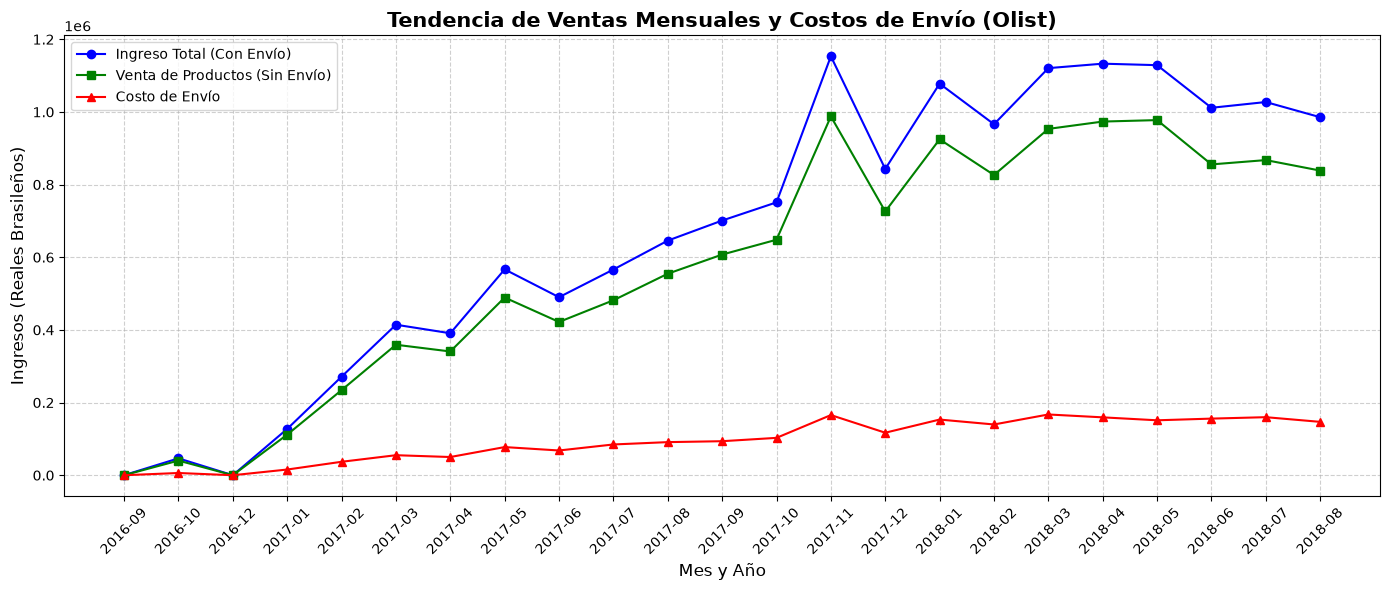

,mes_compra,price,freight_value,total_pagado
0,2016-09,134.97,8.49,143.46
1,2016-10,40325.11,6165.55,46490.66
2,2016-12,10.90,8.72,19.62
3,2017-01,111798.36,15684.01,127482.37
4,2017-02,234223.40,37015.92,271239.32


In [7]:
# Importar librería para crear gráficas
import matplotlib.pyplot as plt

# 1. Agrupar las ventas por mes sumando los ingresos y costos
df_tendencia = df_ventas.groupby('mes_compra')[['price', 'freight_value', 'total_pagado']].sum().reset_index()

# Convertir 'mes_compra' a texto para que la gráfica lo lea correctamente
df_tendencia['mes_compra'] = df_tendencia['mes_compra'].astype(str)

# 2. Configurar el tamaño de la gráfica
plt.figure(figsize=(14, 6))

# 3. Dibujar las 3 líneas (Ingreso total, Solo productos, y Solo envíos)
plt.plot(df_tendencia['mes_compra'], df_tendencia['total_pagado'], label='Ingreso Total (Con Envío)', marker='o', color='blue')
plt.plot(df_tendencia['mes_compra'], df_tendencia['price'], label='Venta de Productos (Sin Envío)', marker='s', color='green')
plt.plot(df_tendencia['mes_compra'], df_tendencia['freight_value'], label='Costo de Envío', marker='^', color='red')

# 4. Personalizar el diseño (títulos, etiquetas y cuadrícula)
plt.title('Tendencia de Ventas Mensuales y Costos de Envío (Olist)', fontsize=15, fontweight='bold')
plt.xlabel('Mes y Año', fontsize=12)
plt.ylabel('Ingresos (Reales Brasileños)', fontsize=12)
plt.xticks(rotation=45) # Inclinar las fechas para que se lean bien
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# 5. Mostrar la gráfica y las primeras filas de la tabla agrupada
plt.show()
display(df_tendencia.head())

## 6. Cruce con Productos y Pregunta de Negocio 2 (Ingresos por Categoría)
**Pregunta 2:** ¿Qué categorías de productos generan los mayores ingresos?

Para resolver esto, cruzaremos nuestra tabla actual de ventas con la tabla de productos (`df_products`) usando la llave `product_id`. Esto nos permitirá conocer el nombre de la categoría de cada artículo vendido y agrupar los ingresos totales para descubrir cuáles son los más rentables.

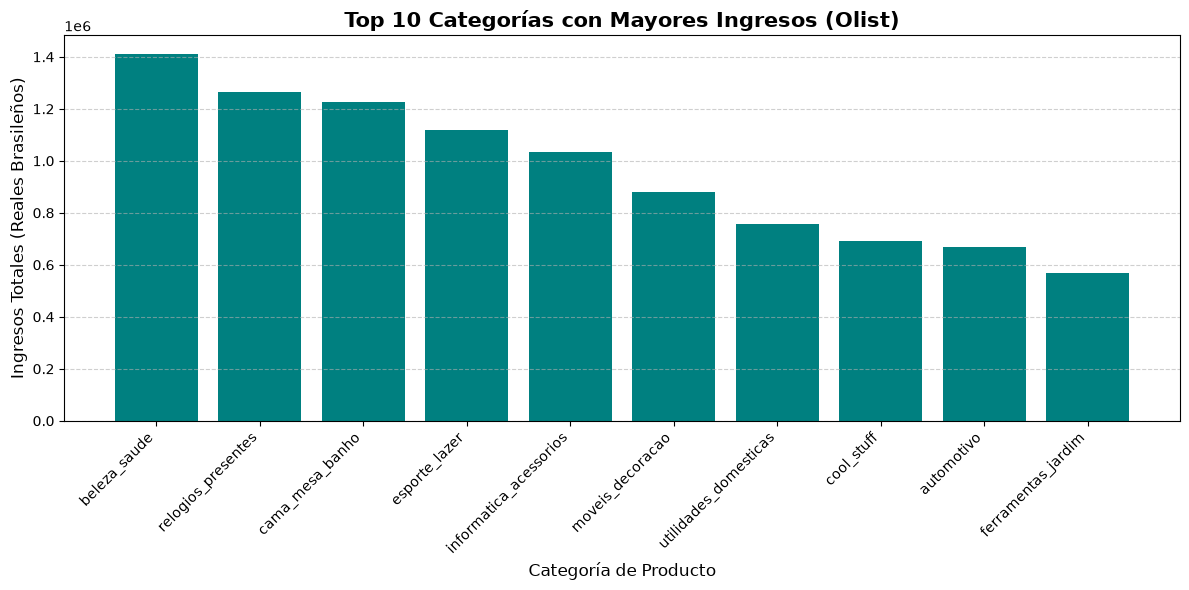

,product_category_name,total_pagado
11,beleza_saude,1412089.53
66,relogios_presentes,1264016.98
13,cama_mesa_banho,1225209.26
32,esporte_lazer,1118062.91
44,informatica_acessorios,1032603.65
54,moveis_decoracao,880329.92
72,utilidades_domesticas,758392.25
26,cool_stuff,691680.89
8,automotivo,669319.92
40,ferramentas_jardim,567145.68


In [8]:
# 1. Cruzar la tabla de ventas con la de productos para obtener las categorías
df_ventas_prod = pd.merge(df_ventas, df_products, on='product_id', how='inner')

# 2. Agrupar por categoría de producto y sumar el total pagado
top_categorias = df_ventas_prod.groupby('product_category_name')['total_pagado'].sum().reset_index()

# 3. Ordenar los resultados de mayor a menor y quedarnos con el Top 10
top_categorias = top_categorias.sort_values(by='total_pagado', ascending=False).head(10)

# 4. Crear una gráfica de barras para visualizar el Top 10
plt.figure(figsize=(12, 6))
plt.bar(top_categorias['product_category_name'], top_categorias['total_pagado'], color='teal')

# Personalizar el diseño
plt.title('Top 10 Categorías con Mayores Ingresos (Olist)', fontsize=15, fontweight='bold')
plt.xlabel('Categoría de Producto', fontsize=12)
plt.ylabel('Ingresos Totales (Reales Brasileños)', fontsize=12)
plt.xticks(rotation=45, ha='right') # Inclinación para que los nombres largos se lean bien
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# Mostrar la gráfica y la tabla
plt.show()
display(top_categorias)

### Análisis de Tiempos de Entrega y Valores Atípicos (Outliers)
Para la segunda parte de la pregunta, calcularemos los días que tardó cada pedido en llegar. Posteriormente, aplicaremos el método estadístico del Rango Intercuartílico (IQR) para definir un límite superior. Cualquier pedido que supere este límite será considerado un *outlier* (una entrega anormalmente tardía).

In [9]:
# 1. Calcular el tiempo de entrega real en días
df_ventas_prod['dias_entrega'] = (df_ventas_prod['order_delivered_customer_date'] - df_ventas_prod['order_purchase_timestamp']).dt.days

# 2. Calcular los cuartiles (Q1 y Q3) y el IQR con numpy
Q1 = np.percentile(df_ventas_prod['dias_entrega'].dropna(), 25)
Q3 = np.percentile(df_ventas_prod['dias_entrega'].dropna(), 75)
IQR = Q3 - Q1

# 3. Definir el límite estadístico superior
limite_superior = Q3 + 1.5 * IQR

# 4. Filtrar los pedidos que sobrepasan el límite (Outliers)
outliers_entrega = df_ventas_prod[df_ventas_prod['dias_entrega'] > limite_superior]

# 5. Mostrar resultados
print(f"El límite para considerar una entrega 'normal' es de {limite_superior} días.")
print(f"Se encontraron {outliers_entrega.shape[0]} pedidos con tiempos de entrega estadísticamente atípicos (outliers).")

print("\nTop 5 categorías con más retrasos extremos:")
display(outliers_entrega['product_category_name'].value_counts().head())

El límite para considerar una entrega 'normal' es de 28.5 días.
Se encontraron 5557 pedidos con tiempos de entrega estadísticamente atípicos (outliers).

Top 5 categorías con más retrasos extremos:


product_category_name
cama_mesa_banho           557
beleza_saude              492
moveis_decoracao          417
informatica_acessorios    415
esporte_lazer             388
Name: count, dtype: int64

## 7. Cruce Geográfico y Pregunta de Negocio 3
**Pregunta 3:** ¿Existe una concentración geográfica de pedidos retrasados según el estado del cliente?

Para descubrir dónde están los peores cuellos de botella logísticos, cruzaremos nuestra tabla de pedidos atípicos (aquellos que tardaron más de 28.5 días) con la tabla de clientes (`df_customers`). Agruparemos los datos por estado para identificar visualmente las regiones más afectadas.

Top 10 estados con mayores retrasos en entregas:


,Estado,Total_Pedidos_Retrasados
0,RJ,1372
1,SP,631
2,BA,491
3,RS,422
4,MG,327
5,SC,280
6,PA,266
7,CE,235
8,PE,196
9,ES,142


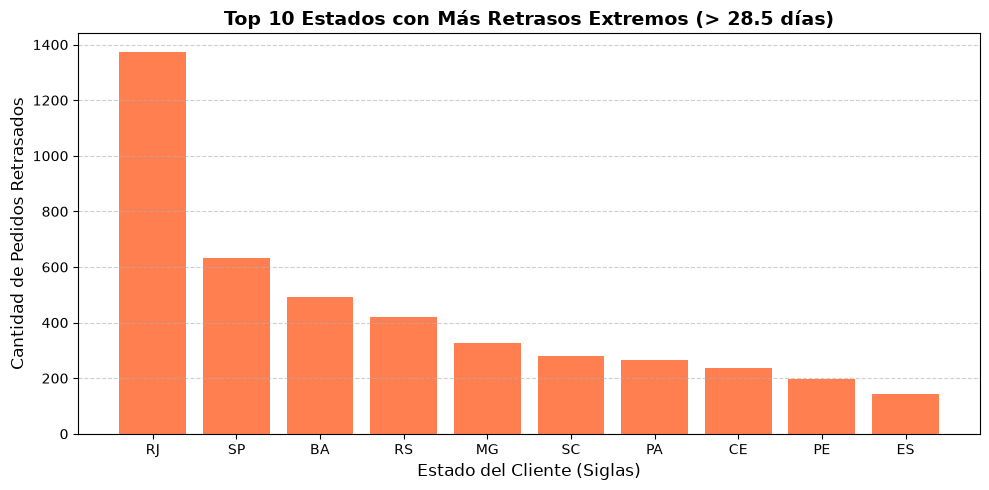

In [10]:
# 1. Cruzar la tabla de outliers (retrasos) con la tabla de clientes
df_retrasos_geo = pd.merge(outliers_entrega, df_customers, on='customer_id', how='inner')

# 2. Agrupar por estado del cliente y contar cuántos pedidos retrasados hay
retrasos_por_estado = df_retrasos_geo['customer_state'].value_counts().reset_index()
retrasos_por_estado.columns = ['Estado', 'Total_Pedidos_Retrasados']

# 3. Mostrar el Top 10 de estados en una tabla
print("Top 10 estados con mayores retrasos en entregas:")
display(retrasos_por_estado.head(10))

# 4. Crear una gráfica de barras para visualizarlo
plt.figure(figsize=(10, 5))
plt.bar(retrasos_por_estado['Estado'][:10], retrasos_por_estado['Total_Pedidos_Retrasados'][:10], color='coral')

# Personalizar el diseño
plt.title('Top 10 Estados con Más Retrasos Extremos (> 28.5 días)', fontsize=14, fontweight='bold')
plt.xlabel('Estado del Cliente (Siglas)', fontsize=12)
plt.ylabel('Cantidad de Pedidos Retrasados', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# Mostrar la gráfica
plt.show()

## 8. Conclusiones Finales
A partir del Análisis Exploratorio de Datos (EDA) realizado, hemos respondido a nuestras preguntas de negocio con los siguientes hallazgos:

1. **Tendencia de Ventas:** Existe un crecimiento constante durante 2017, alcanzando un pico máximo histórico de ingresos en noviembre, lo cual coincide con la alta demanda de la temporada de *Black Friday*.
2. **Categorías Estrella:** El sector de "Belleza y Salud" (*beleza_saude*) es el más rentable de la plataforma, seguido por la categoría de relojes/regalos y artículos de cama/baño.
3. **Logística y Cuellos de Botella:** Al usar el Rango Intercuartílico (IQR), definimos que cualquier entrega que tarde más de 28.5 días es un *outlier* (retraso extremo). El estado de **Río de Janeiro (RJ)** concentra la mayor cantidad de problemas logísticos a nivel nacional, por lo que se recomienda al área de operaciones auditar y mejorar a los proveedores de transporte en esa región específica.